# Análisis de las fuentes y amplitudes de ruido · EKF G/F
## Solubilidad variable · desarrollo exclusivamente con LAB019–021

**Pregunta:** ¿qué estructura de ruido y qué amplitudes están respaldadas por estos ensayos, y qué decisiones siguen siendo supuestos?

No se usan LAB016–018 para ajustar, seleccionar fuentes, inicializar búsquedas ni evaluar alternativas. No se modifican los notebooks previos. La química, la solubilidad y las reglas causales del estimador se mantienen. Las muestras químicas de LAB019–021 son **datos de desarrollo** en este estudio; no son una validación independiente.

El estudio separa: (1) reproducción del EKF existente; (2) recalibración de gas compatible con el operador online; (3) ajuste de ruido; (4) validación interna dejando una fermentación fuera. No se interpretará una mejora del gas como prueba de mejores estados químicos.

**Alcance:** análisis exploratorio, no certificación de parámetros verdaderos. Tres fermentaciones limitan la evidencia. Un óptimo en un límite de búsqueda, la dependencia del inicio o innovaciones correlacionadas impiden presentar las amplitudes como identificadas con precisión.

**Ejecución:** Python con NumPy, pandas, SciPy, matplotlib, nbformat y numba. La ejecución entregada usa el entorno base de Anaconda, que ya dispone de numba. El entorno `fermentation` puede necesitar esa dependencia si se elige para ejecutar este notebook. La compilación acelera las mismas ecuaciones y diferencias finitas; no modifica el filtro ni su paso temporal.

In [1]:
from pathlib import Path
import sys, json, hashlib, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nbformat
from IPython.display import display, Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/wine_fermentation').is_dir())
HERE=ROOT/'notebooks/EKF/kalman_analysis'
sys.path.insert(0,str(HERE))
import analysis_core as core
import analysis_plots as plots
OUT=HERE/'results'
PROTECTED=core.protected_hashes(ROOT)
DATA,CHEM,DATA_AUDIT,RAW_AUDIT=core.prepare(ROOT)
assert tuple(DATA)==('LAB019','LAB020','LAB021')
assert set(CHEM.lab)==set(core.LABS)
display(DATA_AUDIT)
print('All optimization and selection inputs:',list(DATA))
print('No holdout simulations or holdout performance metrics are computed.')

All optimization and selection inputs: ['LAB019', 'LAB020', 'LAB021']
No holdout simulations or holdout performance metrics are computed.


,LAB,horizon_h,windows,updates,X0,N0,G0,F0,E0,pulse_h,dose_g_L
0,LAB019,166.000000,332,217,0.283162,0.230025,79.19,78.97,10.010194,64.333333,0.086486
1,LAB020,172.333333,344,223,0.153342,0.225556,77.94,79.52,10.010194,71.666667,0.088889
2,LAB021,166.000000,332,166,0.270000,0.231202,80.19,81.04,10.010194,47.500000,0.086486


## 1. Procesos, ecuaciones y fuentes candidatas

Definimos $r_c=\mu X$, $r_G=\beta_GX/Y_{E/G}$, $r_F=\beta_FX/Y_{E/F}$, $r_d=k_dX$, $r_m=mX$. Entonces:

\[
\dot X=r_c-r_d,\quad \dot N=-r_c/Y_{X/N},\quad
\dot G=-r_c/Y_{X/G}-r_G-p_Gr_m,\quad
\dot F=-r_c/Y_{X/F}-r_F-p_Fr_m,\quad
\dot E=Y_{E/G}r_G+Y_{E/F}r_F.
\]

$p_G=G/(G+F)$ y $p_F=F/(G+F)$, con las protecciones de denominador del código. La producción es $q_{prod}=r_c/12.72+(Y_{E/G}r_G+Y_{E/F}r_F)/1.05$.

Cada columna de $L$ expresa el efecto de perturbar un flujo. Orden de columnas: crecimiento, fermentación G, fermentación F, CO₂ adicional, mortalidad, mantenimiento. Orden de filas: $[X,N,G,F,E,C_d,I]$. Mortalidad afecta directamente solo a X; mantenimiento consume G/F sin producción directa de etanol ni CO₂ en estas ecuaciones. La cuarta fuente es una discrepancia añadida, no un proceso químico independiente demostrado.

La selección binaria de absorción/emisión para el ruido es una aproximación local heredada; no se identifica aquí como una ley física exacta. Las perturbaciones son aditivas de flujo: pueden actuar aunque un flujo determinista sea pequeño. No equivalen automáticamente a incertidumbres de parámetros cinéticos. Hay que revisar los recortes y la actividad de cada proceso antes de interpretar una fuente como físicamente identificada.

In [2]:
SOURCE_TABLE=pd.DataFrame([
 ['Growth','rc = mu X','+X; -N/Yxn; -G/Yxg; -F/Yxf; +CO2','g biomass/(L sqrt(h))'],
 ['Glucose fermentation','rG = betaG X / Yeg','-G; +Yeg E; +CO2','g glucose/(L sqrt(h))'],
 ['Fructose fermentation','rF = betaF X / Yef','-F; +Yef E; +CO2','g fructose/(L sqrt(h))'],
 ['Additional CO2','Production discrepancy','Cd or gas integral through transfer','g CO2/(L sqrt(h))'],
 ['Mortality','rd = kd X','-X only directly','g biomass/(L sqrt(h))'],
 ['Maintenance','rm = m X','-pG G; -pF F','g sugar/(L sqrt(h))'],
],columns=['Source','Model term','Mapping','Diffusion-amplitude units'])
display(SOURCE_TABLE)
display(pd.Series(core.THETA,name='Frozen chemical parameters'))

,Source,Model term,Mapping,Diffusion-amplitude units
0,Growth,rc = mu X,+X; -N/Yxn; -G/Yxg; -F/Yxf; +CO2,g biomass/(L sqrt(h))
1,Glucose fermentation,rG = betaG X / Yeg,-G; +Yeg E; +CO2,g glucose/(L sqrt(h))
2,Fructose fermentation,rF = betaF X / Yef,-F; +Yef E; +CO2,g fructose/(L sqrt(h))
3,Additional CO2,Production discrepancy,Cd or gas integral through transfer,g CO2/(L sqrt(h))
4,Mortality,rd = kd X,-X only directly,g biomass/(L sqrt(h))
5,Maintenance,rm = m X,-pG G; -pF F,g sugar/(L sqrt(h))


mu0        0.094031
betaG0     0.422437
betaF0     0.623655
Kn0        0.008258
Kg0        4.400775
Kf0       19.296084
Kig0      65.019939
Kie0      96.265166
Kd0        0.000440
Yxn        6.456226
Yxg        0.966094
Yxf        1.109896
Yeg        0.468459
Yef        0.511328
m0         0.018339
Name: Frozen chemical parameters, dtype: float64

## 2. Referencia reproducida antes de ajustar

Se conservan las medias RAW de 30 minutos, criterios de cobertura/umbral, temperatura del último minuto completado, volumen remanente, nutriciones y condiciones iniciales del EKF existente. Se preservan $P_0$, Joseph, las diferencias finitas y RK4 a un minuto sobre la malla de propagación de cinco minutos. El acumulador I se reinicia tras cada ventana.

Comparamos los RMSE con los resultados guardados en el notebook existente **solo para LAB019–021**. Esta comprobación no selecciona parámetros. La prueba de desarrollo también compara un paso RK4 de medio minuto para evaluar sensibilidad numérica. No se asimilan muestras químicas. Se incluyen las muestras NUT en RMSE y se conserva la exclusión de G+F sustituido por cero. Los iniciales se muestran, pero no entran al RMSE postinicial.

In [3]:
ARCHIVED={lab:core.run(DATA[lab]) for lab in core.LABS}
base_metrics=pd.concat([core.diagnostics(DATA,CHEM,lab,ARCHIVED[lab])[0] for lab in core.LABS],ignore_index=True)
reference=nbformat.read(ROOT/'notebooks/EKF/05_zenteno_co2_variable_solubility.executed.ipynb',as_version=4)
reference_rows=None
for cell in reference.cells:
    for output in cell.get('outputs',[]):
        for line in output.get('text','').splitlines():
            if line.startswith('METRICS_VARIABLE_JSON '):reference_rows=json.loads(line.split(' ',1)[1])
assert reference_rows is not None
prior=pd.DataFrame(reference_rows)
for row in base_metrics.itertuples():
    if row.variable in ('G','F'):continue
    expected=prior.loc[prior.LAB.eq(row.LAB)&prior.variable.eq(row.variable)&prior.caso.eq('forecast' if row.variable=='CO2' else 'EKF_')]
    assert len(expected)==1 and abs(expected.RMSE.iloc[0]-row.RMSE)<1e-7
assert base_metrics.loc[base_metrics.variable.eq('N'),'n'].eq(12).all()
refinement=[]
for lab in core.LABS:
    fine=core.run(DATA[lab],step=1/120)
    refinement.append(dict(LAB=lab,max_CO2_difference=float(np.nanmax(abs(fine[2][:,0]-ARCHIVED[lab][2][:,0]))),
        max_physical_state_difference=float(np.max(abs(fine[0][:,:6]-ARCHIVED[lab][0][:,:6])))))
display(base_metrics)
display(pd.DataFrame(refinement))
print('Archived RMSE reproduced; all 12 post-initial YAN observations included per LAB.')

Archived RMSE reproduced; all 12 post-initial YAN observations included per LAB.


,LAB,variable,unit,n,RMSE,MAE,coverage95
0,LAB019,CO2,g/(L h),332,0.064583,0.048202,NaN
1,LAB019,X,g/L,10,0.658065,0.538373,0.200000
2,LAB019,N,mg/L,12,20.243967,16.023887,0.500000
3,LAB019,G,g/L,7,4.063933,3.255994,0.857143
4,LAB019,F,g/L,7,5.467386,5.324787,0.571429
5,LAB019,GF,g/L,10,7.968872,7.138081,0.200000
6,LAB019,E,g/L,5,4.245199,3.357556,0.600000
7,LAB020,CO2,g/(L h),344,0.072030,0.057326,NaN
8,LAB020,X,g/L,10,0.572336,0.402527,0.400000
9,LAB020,N,mg/L,12,18.395281,14.424613,0.500000


,LAB,max_CO2_difference,max_physical_state_difference
0,LAB019,0.000526,0.016701
1,LAB020,0.000201,0.002782
2,LAB021,0.000048,0.000387


## 3. Qué es fijo y qué se estima

En unidades físicas $Q=L\operatorname{diag}(\sigma_j^2)L^T$. En el código se escala y se añade $Q\Delta t$ a la covarianza propagada. Las amplitudes son desviaciones de difusión por raíz de hora; no son desviaciones estándar de las concentraciones iniciales ni porcentajes.

$P_0$ se mantiene: $\sigma_X=\max(0.03,0.2X_0)$, $\sigma_N=0.015$ g/L, $\sigma_E=2$ g/L, varG=12.5, varF=37.5, cov(G,F)=-12.5; varCd=varI=0. No se añade incertidumbre independiente a temperatura, presión ni dosis. Son limitaciones explícitas.

Los parámetros `growth`, `fermentation` y `gas` son multiplicadores de amplitudes originales. `mortality`, `maintenance` y `R` son amplitudes absolutas. `R` significa aquí la desviación estándar; la covarianza de observación usada es su cuadrado. La alternativa Separate G/F separa los multiplicadores de ambas fermentaciones. No se ajustan libremente 49 entradas de Q.

Bounds are exploratory search constraints, not experimentally determined uncertainty intervals.


,structure,parameters,count
0,Current,"growth, fermentation, gas, R",4
1,+ mortality,"growth, fermentation, gas, mortality, R",5
2,+ maintenance,"growth, fermentation, gas, maintenance, R",5
3,+ both,"growth, fermentation, gas, mortality, maintena...",6
4,Separate G/F,"growth, ferm_G, ferm_F, gas, R",5
5,No extra CO2,"growth, fermentation, R",3


,parameter,lower,upper
0,growth,0.01000,10.000000
1,fermentation,0.01000,10.000000
2,gas,0.01000,10.000000
3,mortality,0.00001,0.100000
4,maintenance,0.00010,1.000000
5,R,0.00100,0.199526


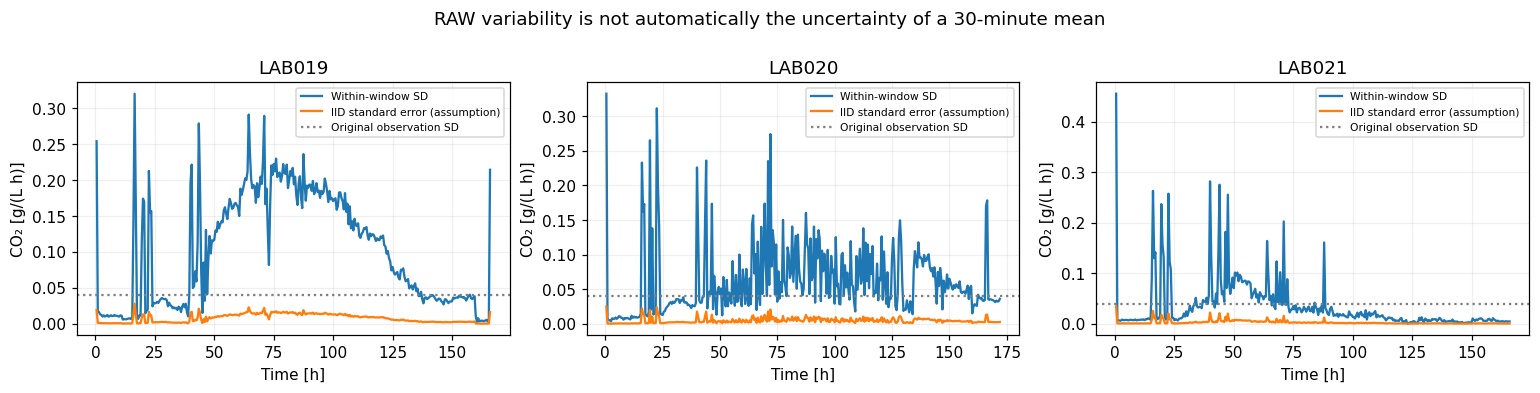

,raw_SD,naive_SE,lag1,half_difference
LAB,,,,
LAB019,0.097687,0.007406,0.964002,-0.000644
LAB020,0.045734,0.003474,0.965602,0.000316
LAB021,0.014617,0.001108,0.895889,0.000149


In [4]:
display(pd.DataFrame([dict(structure=k,parameters=', '.join(v),count=len(v)) for k,v in core.STRUCTURES.items()]))
display(pd.DataFrame([dict(parameter=k,lower=10**lo,upper=10**hi) for k,(lo,hi) in core.LOG_BOUNDS.items()]))
print('Bounds are exploratory search constraints, not experimentally determined uncertainty intervals.')
plots.raw_noise(RAW_AUDIT)
display(RAW_AUDIT.groupby('LAB')[['raw_SD','naive_SE','lag1','half_difference']].median())

## 3R. Justificación de R: fabricante, adquisición y LAB019–021

**Esta sección nueva estudia R sin reajustar Q ni elegir fuentes.** Los resultados de optimización que aparecen más adelante conservan sus supuestos históricos; no se recalibran automáticamente con estos escenarios.

### Evidencia documental

| Documento del repositorio | Ubicación | Especificación relevante |
|---|---|---|
| [Ficha FMA-A2000](../../../references/Sensor_omega/FMAA2100_2200_2300_2400.pdf) | PDF p. 2 | Exactitud ±1 % del fondo de escala, incluida linealidad; repetibilidad ±0,15 % FS; respuesta 5 s |
| [Manual M2842](../../../references/Sensor_omega/M2842.pdf) | PDF pp. 5, 8–10 | Exactitud ±1 % FS; comprobar cero y calentar 5–10 min; al convertir gases mediante K se indica ±4 % sin base porcentual explícita en esa sección; K(CO₂)/K(N₂)=0,74 en la tabla |
| GUI archivada | `references/codigo_GUI/NEW_GUI_filtrado_vFINAL.py`, configuración y `current_to_flow_sccm` | Escala predeterminada 0–50 SCCM; recorte 4–20 mA; conversión de gas 0,74 y volumen molar 24,16 L/mol |

El manual indica una respuesta de 1–2 s, distinta de la ficha. Ninguno de estos tiempos garantiza independencia entre registros. La inspección de la tabla de factores del PDF confirma 0,74; el equipo está calibrado con aire y el factor 0,74 fue confirmado correcto por el usuario. No cambiamos la señal actual.

**Configuración confirmada explícitamente por el usuario el 2026-11-05:** rango 0–50 SCCM, calibración con aire y factor a CO₂ 0,74 correcto. Estos hechos están registrados en `configs/co2_instrument.json` y no se vuelven a solicitar. Los registros corroboran además la conversión del software. Esta confirmación no aporta por sí sola una desviación estándar de medición ni resuelve la base del ±4 % del manual. Las especificaciones no incluyen por sí solas toda la incertidumbre del shunt, ADC, volumen, composición/humedad y factor de gas.

### Qué representa R en este estimador

La observación es la media nativa RAW de una ventana completa de 30 minutos, convertida a g/(L h):

\[
y_k=\frac1{n_k}\sum_i c_i f_i,\qquad
c_i=\frac{44.0095\,60\,0.74}{1000\,24.16\,V_i}.
\]

Por tanto, $R_k$ representa la varianza del **error de esa media**, no la varianza de los caudales instantáneos ni el cuadrado de un porcentaje sin conversión.

Si los errores fueran independientes: $R_k=n_k^{-2}\sum_i c_i^2\operatorname{Var}(e_i)$. Con correlación, también intervienen los términos $c_ic_j\operatorname{Cov}(e_i,e_j)$. Un error de cero común a toda la ventana aporta $(\operatorname{mean}c_i)^2u_b^2$: **no disminuye con $\sqrt n$** y puede correlacionar ventanas sucesivas.

La exactitud ±1 % FS no está especificada como una desviación estándar. Para un escenario tipo B asumimos distribución rectangular: $u=a/\sqrt3$. La suposición está identificada, no atribuida al fabricante. Referencia: [NIST, evaluación tipo B](https://physics.nist.gov/cuu/Uncertainty/typeb.html).

Con FS=50 SCCM, el semiancho de exactitud es 0,5 SCCM. Su conversión a 2 L da ±0,02022 g/(L h), o $u\approx0,01167$ bajo esa suposición. La repetibilidad se muestra separadamente: no se suma automáticamente a una exactitud que ya puede incluirla.

### Método empírico y limitaciones

Se conservan todas las muestras de las ventanas válidas y las medias originales. Se comparan residuos tras retirar una tendencia lineal y tras retirar solo la media. Se estima la varianza de la media con covarianzas de rezagos y ponderación Bartlett (HAC), variando el ancho entre 30 s, 2, 5 y 10 min. La conversión de tiempo a número de rezagos usa la cadencia mediana; la irregularidad se audita.

Esto **no separa ruido instrumental y fluctuaciones reales de fermentación**. No es una medición contra un patrón ni una estimación exacta de error del promedio. El detrend y el ancho son supuestos de diagnóstico. El tramo preinoculación tampoco se considera automáticamente una referencia de flujo cero, y las lecturas recortadas a cero no demuestran varianza nula. Los picos se diagnostican sin eliminarlos ni cambiar el operador de medida.


Original observation standard deviation = 0.04; original R = 0.0016
User-confirmed configuration: 0–50 SCCM; calibration gas = air; CO2 factor = 0.74.


,LAB,interior_points,flow_per_mA,offset_sccm,inferred_span_sccm,reconstruction_max_sccm,clipped_below_4mA_fraction,clipped_upper_fraction,range_and_calibration_gas_confirmed
0,LAB019,49244,3.125,-12.500000,49.999999,0.000200,0.127807,0.000067,True
1,LAB020,49399,3.125,-12.500001,50.000004,0.000200,0.146628,0.000130,True
2,LAB021,42072,3.125,-12.499998,49.999995,0.000188,0.179390,0.000101,True


,LAB,label,n,median_current_mA,median_flow_sccm,below_4mA_fraction
0,LAB019,"Pre-inoculation, not a certified zero",1583,4.0912,0.2851,0.003159
1,LAB020,"Pre-inoculation, not a certified zero",1583,4.0152,0.0473,0.246999
2,LAB021,"Pre-inoculation, not a certified zero",1583,4.0653,0.2039,0.001263


,volume_L,conversion,one_pct_FS_half_width,one_pct_rectangular_u,repeat_rectangular_u,four_pct_FS_half_width,four_pct_FS_rectangular_u,original_SD
0,2.0,0.040439,0.020220,0.011674,0.001751,0.080878,0.046695,0.04
1,1.8,0.044932,0.022466,0.012971,0.001946,0.089865,0.051884,0.04
2,1.5,0.053919,0.026959,0.015565,0.002335,0.107838,0.062260,0.04


,LAB,subset,quantity,n,q10,median,q90,maximum
12,LAB019,Assimilated,iid_SE,217,0.002339,0.011644,0.015352,0.026466
13,LAB019,Assimilated,linear_HAC_SE_30s,217,0.004485,0.021613,0.029957,0.038959
14,LAB019,Assimilated,linear_HAC_SE_120s,217,0.007376,0.033535,0.048345,0.055823
15,LAB019,Assimilated,linear_HAC_SE_300s,217,0.008724,0.038857,0.056540,0.071602
16,LAB019,Assimilated,linear_HAC_SE_600s,217,0.006218,0.022529,0.040747,0.062720
17,LAB019,Assimilated,constant_HAC_SE_120s,217,0.007941,0.034283,0.050092,0.057960
18,LAB019,Assimilated,accuracy_rectangular_u,217,0.012288,0.012971,0.013341,0.013341
19,LAB019,Assimilated,repeatability_rectangular_u,217,0.001843,0.001946,0.002001,0.002001
20,LAB019,Assimilated,K4pct_reading_rectangular_u,217,0.001828,0.009708,0.015189,0.018761
21,LAB019,Assimilated,K4pct_FS_rectangular_u,217,0.049153,0.051884,0.053366,0.053366


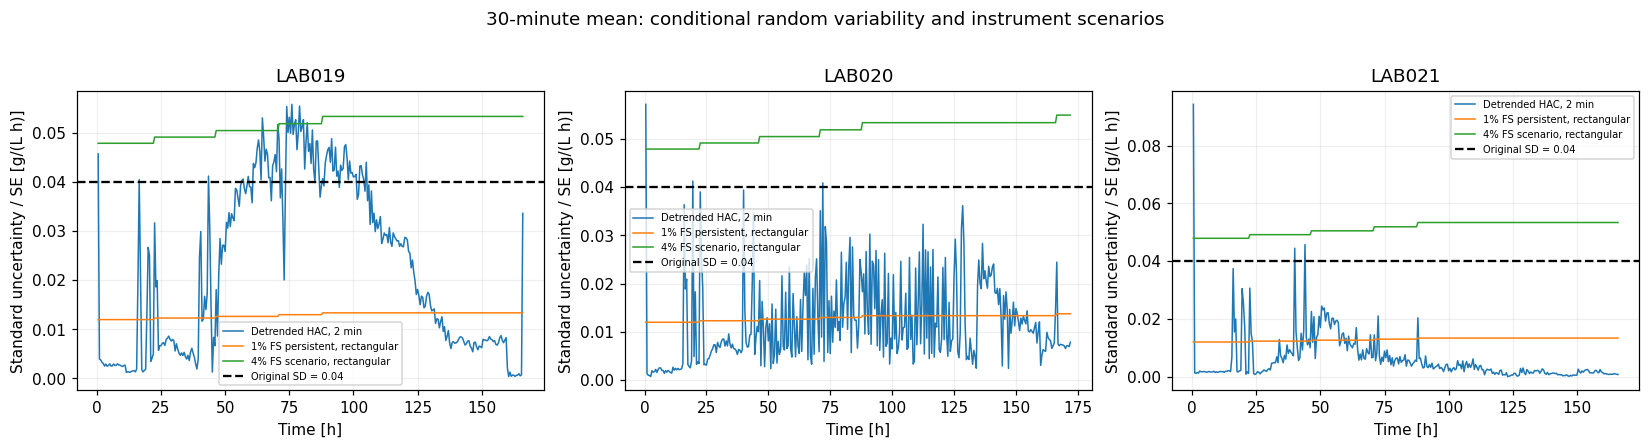

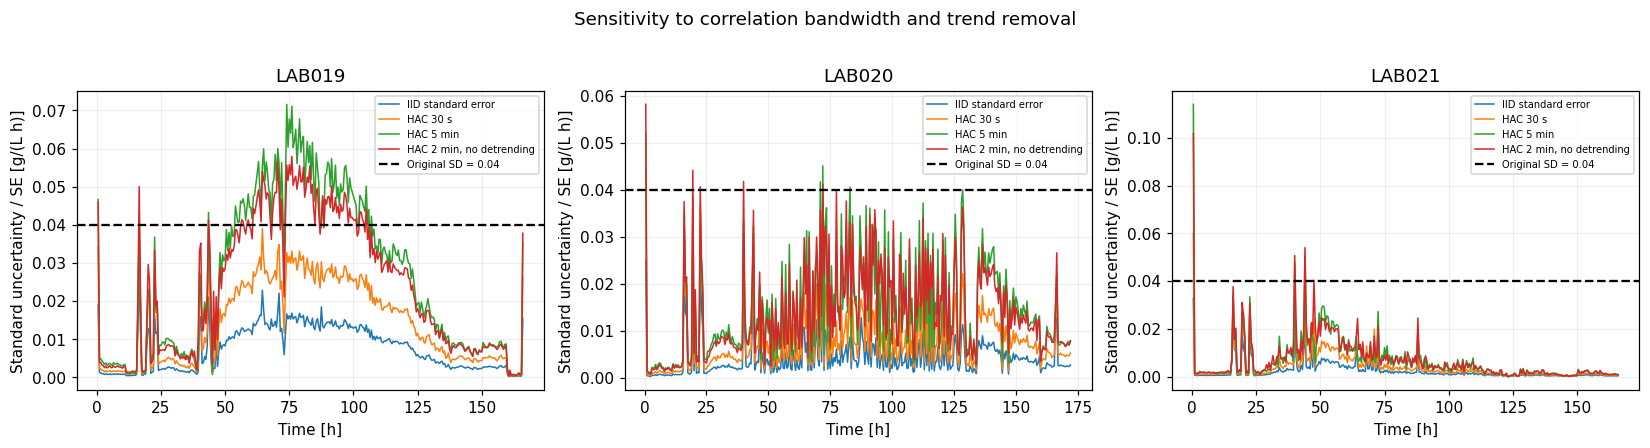

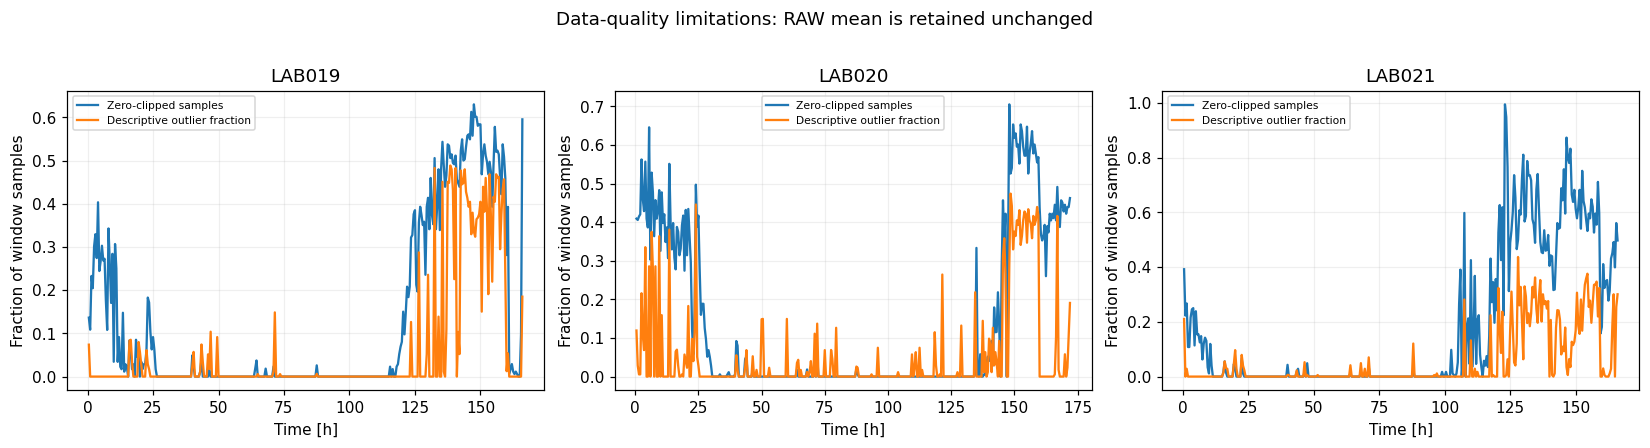

In [5]:
import r_assessment as ra
R_WINDOWS,R_CHAIN,R_PRE,R_SUMMARY,R_TYPEB,R_EVIDENCE=ra.audit(ROOT,DATA,OUT)
assert set(R_WINDOWS.LAB)==set(core.LABS)
display(R_CHAIN)
display(R_PRE)
display(R_TYPEB)
display(R_SUMMARY.loc[R_SUMMARY.subset.eq('Assimilated')])
ra.figures(R_WINDOWS)
print('Original observation standard deviation = 0.04; original R =',0.04**2)
print('User-confirmed configuration: 0–50 SCCM; calibration gas = air; CO2 factor = 0.74.')


### Escenarios de trabajo, no una calibración metrológica certificada

Se muestran dos envolventes operativas: $R_{k,1\%}=\max(\widehat v_{k,HAC},u_{1\%FS,k}^2)$ y un escenario conservador que interpreta el ±4 % como FS. **El máximo es una regla de exploración, no la fórmula de una covarianza combinada demostrada.** Evita sumar componentes posiblemente solapados, pero no identifica sus covarianzas ni modela los sesgos persistentes. Si un error de calibración es común a múltiples ventanas, representarlo solo por una R diagonal temporal es una aproximación.

Para el ±4 % del método K se muestran dos interpretaciones: porcentaje de lectura y porcentaje FS. La sección del manual no define explícitamente la base; no escogemos una como hecho. Si el ±4 % ya resume la incertidumbre del método, no se añade otra vez el ±1 % para crear una precisión ficticia.

La comparación con 0,04 permite evaluar si el valor original es conservador o insuficiente según cada supuesto y laboratorio. **No convierte 0,04 en una especificación del equipo ni demuestra que una única R constante sirva en toda la fermentación.**


In [6]:
R_TABLE=[]
for lab in core.LABS:
    g=R_WINDOWS.loc[R_WINDOWS.LAB.eq(lab)&R_WINDOWS.assimilate]
    R_TABLE.append(dict(LAB=lab,n=len(g),median_random_HAC_SD=g.linear_HAC_SE_120s.median(),
        median_accuracy_typeB_SD=g.accuracy_rectangular_u.median(),
        working_1pct_moment_SD=float(np.sqrt(g.R_working_1pct_persistent.mean())),
        working_4pctFS_moment_SD=float(np.sqrt(g.R_working_4pct_FS_persistent.mean())),
        fraction_HAC_above_original=float(g.linear_HAC_SE_120s.gt(.04).mean()),
        zero_clip_fraction_median=g.zero_fraction.median(),lag1_median=g.lag1.median()))
R_TABLE=pd.DataFrame(R_TABLE);display(R_TABLE)
R_TABLE.to_csv(OUT/'R_laboratory_comparison.csv',index=False)
# Equal LAB weighting, rather than weighting laboratories by their record counts.
R_WORKING_1PCT=float(np.mean(R_TABLE.working_1pct_moment_SD**2))
R_WORKING_4PCT_FS=float(np.mean(R_TABLE.working_4pctFS_moment_SD**2))
print('Conditional 1% FS + empirical envelope: sigma =',np.sqrt(R_WORKING_1PCT),'R =',R_WORKING_1PCT)
print('Conditional 4% FS + empirical envelope: sigma =',np.sqrt(R_WORKING_4PCT_FS),'R =',R_WORKING_4PCT_FS)
print('These are working summaries, not two new approved calibrations.')
display(Markdown('**Conclusión de esta sección:** se reemplaza la justificación ausente por evidencia y escenarios explícitos. El valor histórico 0,04 no proviene del datasheet. La serie muestra correlación y variabilidad dependiente de laboratorio/fase; la incertidumbre instrumental pura y el error de conversión de gas no quedan identificados de forma única. El rango, la calibración con aire y el factor 0,74 ya están confirmados por el usuario. Para fijar R antes de reajustar Q queda decidir qué componente persistente se tratará separadamente y cómo representar la incertidumbre del método K. Mientras tanto se conservan 0,04 y los escenarios como referencias de sensibilidad, sin adoptar automáticamente otro valor ni reoptimizar Q.'))
# Independent checks of the variance calculation and unit propagation.
probe=np.array([1.,2.,4.,3.,8.]);assert abs(ra.mean_variance_hac(probe,0)-np.var(probe)/len(probe))<1e-12
assert ra.mean_variance_hac(np.ones(100),20)==0
for bandwidth in [0,1,2,4]:
    assert ra.mean_variance_hac(probe,bandwidth)>=0
    assert np.isclose(ra.mean_variance_hac(3*probe,bandwidth),9*ra.mean_variance_hac(probe,bandwidth))
assert np.isclose(R_TYPEB.loc[R_TYPEB.volume_L.eq(2.),'one_pct_rectangular_u'].iloc[0],ra.FACTOR/2*.5/np.sqrt(3))
print('R audit checks passed; recorded RAW means preserved; allowed labs:',list(core.LABS))


Conditional 1% FS + empirical envelope: sigma = 0.024340216680575153 R = 0.0005924461480573489
Conditional 4% FS + empirical envelope: sigma = 0.05146918963279903 R = 0.0026490774814570267
These are working summaries, not two new approved calibrations.
R audit checks passed; recorded RAW means preserved; allowed labs: ['LAB019', 'LAB020', 'LAB021']


,LAB,n,median_random_HAC_SD,median_accuracy_typeB_SD,working_1pct_moment_SD,working_4pctFS_moment_SD,fraction_HAC_above_original,zero_clip_fraction_median,lag1_median
0,LAB019,217,0.033535,0.012971,0.034745,0.051705,0.373272,0.0,0.974576
1,LAB020,223,0.010988,0.013341,0.018093,0.052038,0.004484,0.0,0.964710
2,LAB021,166,0.006800,0.012620,0.015582,0.050655,0.012048,0.0,0.865175


**Conclusión de esta sección:** se reemplaza la justificación ausente por evidencia y escenarios explícitos. El valor histórico 0,04 no proviene del datasheet. La serie muestra correlación y variabilidad dependiente de laboratorio/fase; la incertidumbre instrumental pura y el error de conversión de gas no quedan identificados de forma única. El rango, la calibración con aire y el factor 0,74 ya están confirmados por el usuario. Para fijar R antes de reajustar Q queda decidir qué componente persistente se tratará separadamente y cómo representar la incertidumbre del método K. Mientras tanto se conservan 0,04 y los escenarios como referencias de sensibilidad, sin adoptar automáticamente otro valor ni reoptimizar Q.

### Separación respecto a los resultados anteriores

Las secciones 4–10 que siguen documentan el estudio exploratorio anterior: allí R se optimizó como incertidumbre efectiva junto con Q. **Esos R ajustados no son estimaciones nuevas de la precisión del medidor** y no se han reemplazado ni recalculado con los escenarios de esta sección. Los artefactos `R_*` son la evidencia añadida para decidir el siguiente ajuste.


La dispersión dentro de una ventana mezcla ruido instrumental, fluctuaciones reales, tendencia y picos. `naive_SE` supone muestras independientes y **no se utiliza para fijar R**. La autocorrelación y la diferencia entre mitades muestran por qué dividir por la raíz del número de muestras puede ser engañoso. Sin réplicas instrumentales/referencia independiente, el R ajustado será una incertidumbre efectiva, no una certificación metrológica. No se elimina ningún pico ni se introduce un nuevo tratamiento RAW en este estudio.

## 4. Ajuste y validación interna

Se reajusta kLa/ganancia por perfil y ganancia analítica en cada partición, usando únicamente sus laboratorios de entrenamiento. **A diferencia de la calibración archivada con medianas horarias y temperatura offline, estas recalibraciones usan el operador causal de 30 minutos y la inicialización online de etanol.** Se muestra por separado el cambio de gas y el de ruido; no se atribuyen ambos cambios a Q.

Después se optimizan las amplitudes positivas en escala logarítmica con dos inicializaciones deterministas y búsqueda acotada. Un ajuste sin convergencia, en un límite o dependiente del inicio se marca y no constituye un valor identificado definitivo.

El objetivo usa innovaciones previas a corregir: $\frac12\operatorname{mean}[\log(2\pi S_k)+\nu_k^2/S_k]$, con igual peso por LAB. **Es un criterio gaussiano aproximado condicionado a las ventanas elegibles, no la verosimilitud exacta de todos los datos:** hay recortes, no linealidades y selección de ventanas dependiente del CO₂ medido. También se reporta RMSE sobre todas las ventanas válidas.

Se dejan fuera LAB019, LAB020 y LAB021 por turnos. Dentro de cada ajuste de ruido también se deja fuera ese laboratorio de la calibración de gas. Las métricas químicas pueden informar la decisión de desarrollo, pero no entran al objetivo numérico ni a las correcciones. El menor criterio de CO₂ identifica un **candidato**, no una aprobación automática de su estructura.

In [7]:
fingerprint=core.study_fingerprint(DATA,CHEM)
cache=OUT/'study.json'
if cache.exists() and json.loads(cache.read_text()).get('fingerprint')==fingerprint:
    STUDY=json.loads(cache.read_text());pack=np.load(OUT/'development_trajectories.npz');RECORDS={}
    for structure in [*core.STRUCTURES,'Original noise']:
        for lab in core.LABS:
            key=structure.replace(' ','_').replace('+','plus').replace('/','_')+'__'+lab
            RECORDS[structure,lab]=tuple(pack[key+'__'+suffix] for suffix in ('frame','covariance','diagnostics'))
    print('Loaded verified results for these exact training data and analysis code.')
else:
    STUDY,RECORDS=core.perform_study(DATA,CHEM,OUT,workers=3)
assert tuple(STUDY['allowed_labs'])==core.LABS
SCORES=pd.DataFrame(STUDY['scores']);METRICS=pd.DataFrame(STUDY['metrics']);CHECKS=pd.DataFrame(STUDY['checks'])
LEADER=STUDY['leader']
display(pd.DataFrame(STUDY['gas']))
display(SCORES)
print('Provisional CO2-score candidate:',LEADER)
print('All labels are development or internal validation, never external holdout.')
# Separate the gas-refit effect from the noise-fit effect on development errors.
comparison=[base_metrics.assign(case='Archived gas + original noise')]
for name in ['Original noise','Current']:
    comparison.append(METRICS.loc[METRICS.fold.eq('All development')&METRICS.structure.eq(name)].assign(case='Refitted gas + '+name))
display(pd.concat(comparison).groupby(['variable','unit','case']).RMSE.mean().unstack('case').round(4))


Loaded verified results for these exact training data and analysis code.
Provisional CO2-score candidate: + mortality
All labels are development or internal validation, never external holdout.


,fold,training,kLa,gain,MSE
0,All development,"LAB019, LAB020, LAB021",0.136362,0.655474,0.016082
1,Leave LAB019 out,"LAB020, LAB021",0.174748,0.648613,0.017721
2,Leave LAB020 out,"LAB019, LAB021",0.136783,0.680763,0.021521
3,Leave LAB021 out,"LAB019, LAB020",0.093693,0.634596,0.008630


,fold,structure,score,training_score,parameters,Rsd,at_bound,converged
0,All development,Current,-1.066703,-1.066703,4,0.067306,growth,True
1,All development,+ mortality,-1.692238,-1.692238,5,0.032632,mortality,True
2,All development,+ maintenance,-1.316240,-1.316240,5,0.046840,"growth, fermentation, gas, maintenance",True
3,All development,+ both,-1.691888,-1.691888,6,0.032299,mortality,True
4,All development,Separate G/F,-1.068544,-1.068544,5,0.068059,growth,True
5,All development,No extra CO2,-1.068004,-1.068004,3,0.070299,growth,True
6,Leave LAB019 out,Current,-1.318130,-0.968824,4,0.067198,growth,True
7,Leave LAB019 out,+ mortality,-1.744834,-1.674357,5,0.030625,mortality,True
8,Leave LAB019 out,+ maintenance,-1.348153,-1.289546,5,0.044864,"growth, fermentation, maintenance",True
9,Leave LAB019 out,+ both,-1.605454,-1.697737,6,0.012299,mortality,True


,case,Archived gas + original noise,Refitted gas + Current,Refitted gas + Original noise
variable,unit,,,
CO2,g/(L h),0.0748,0.0651,0.0713
E,g/L,3.5754,3.4983,3.3706
F,g/L,5.3606,5.1316,5.5186
G,g/L,4.9335,6.0020,5.2264
GF,g/L,8.1840,8.6083,8.8953
N,mg/L,17.2865,30.0714,33.3279
X,g/L,0.7229,0.7099,0.7090


## 5. Relación entre procesos y fuentes

La actividad se calcula sobre la trayectoria de referencia con el gas reajustado y el ruido original. Los valores integrados son descriptivos de esa estimación, no mediciones independientes de los flujos. Una fuente aditiva puede seguir perturbando el sistema aunque el flujo determinista se anule; esto debe distinguirse de atribuirle una incertidumbre a un parámetro cinético.

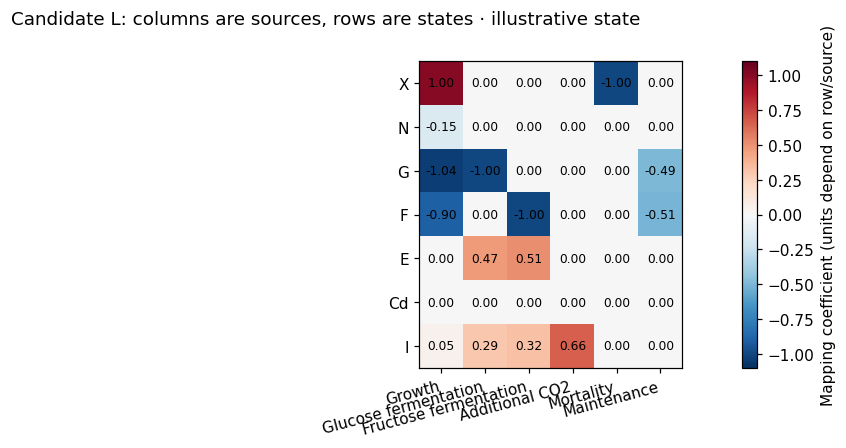

,Growth,Glucose fermentation,Fructose fermentation,Additional CO2,Mortality,Maintenance
X,1.000000,0.000000,0.000000,0.000000,-1.0,0.000000
N,-0.154889,0.000000,0.000000,0.000000,0.0,0.000000
G,-1.035096,-1.000000,0.000000,0.000000,0.0,-0.491817
F,-0.900985,0.000000,-1.000000,0.000000,0.0,-0.508183
E,0.000000,0.468459,0.511328,0.000000,0.0,0.000000
Cd,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
I,0.051531,0.292441,0.319202,0.655474,0.0,0.000000


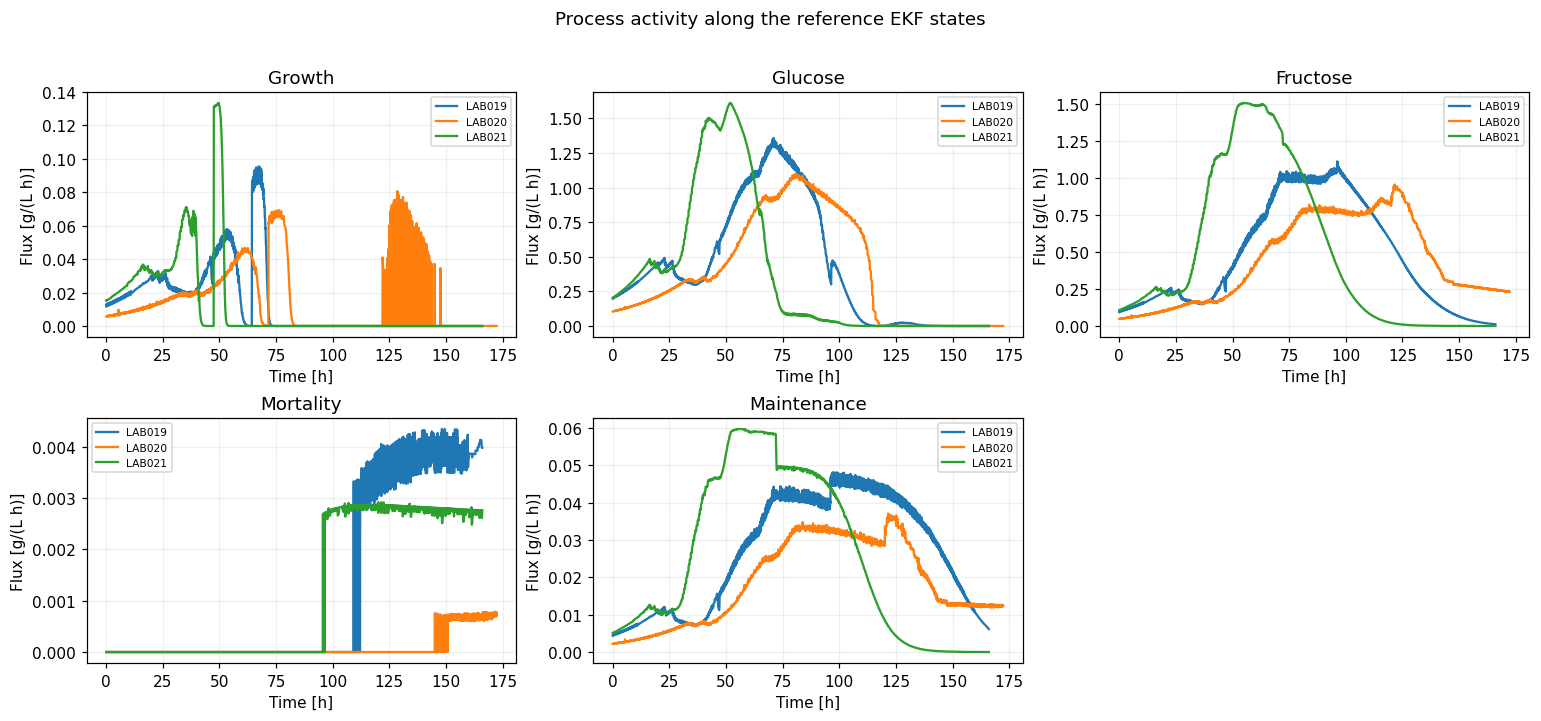

,LAB,process,max_flux,active_fraction,integral_g_L
0,LAB019,Growth,0.095568,0.680883,2.211009
1,LAB019,Glucose,1.358756,0.984947,70.113910
2,LAB019,Fructose,1.111334,1.000000,77.121178
3,LAB019,Mortality,0.004349,0.332664,0.204976
4,LAB019,Maintenance,0.048148,1.000000,4.443120
5,LAB020,Growth,0.080735,0.709522,2.196937
6,LAB020,Glucose,1.100095,0.715321,66.987476
7,LAB020,Fructose,0.955298,1.000000,75.350902
8,LAB020,Mortality,0.000785,0.141131,0.016738
9,LAB020,Maintenance,0.037116,1.000000,3.207581


In [8]:
display(plots.mapping(DATA,RECORDS,np.array([STUDY['gas'][0]['kLa'],STUDY['gas'][0]['gain']])))
ACTIVITY=plots.activity(DATA,RECORDS)
display(ACTIVITY)
ACTIVITY.to_csv(OUT/'process_activity.csv',index=False)

## 6. Rendimiento fuera del ajuste de cada partición

La selección de una estructura no puede basarse únicamente en la mejora del CO₂. Los RMSE de estados químicos se presentan por variable y unidad, sin sumarlos arbitrariamente. Estos tres conjuntos de validación interna son pequeños; la elección final necesita ensayos independientes.

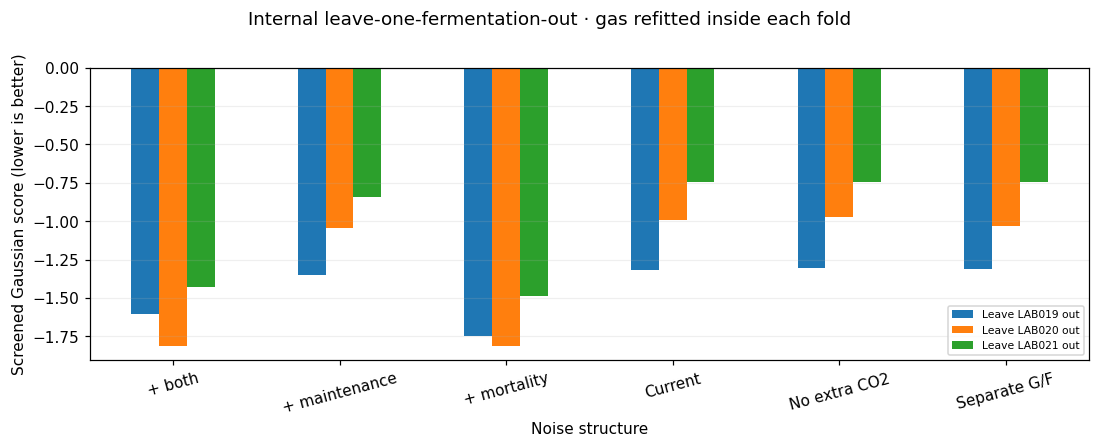

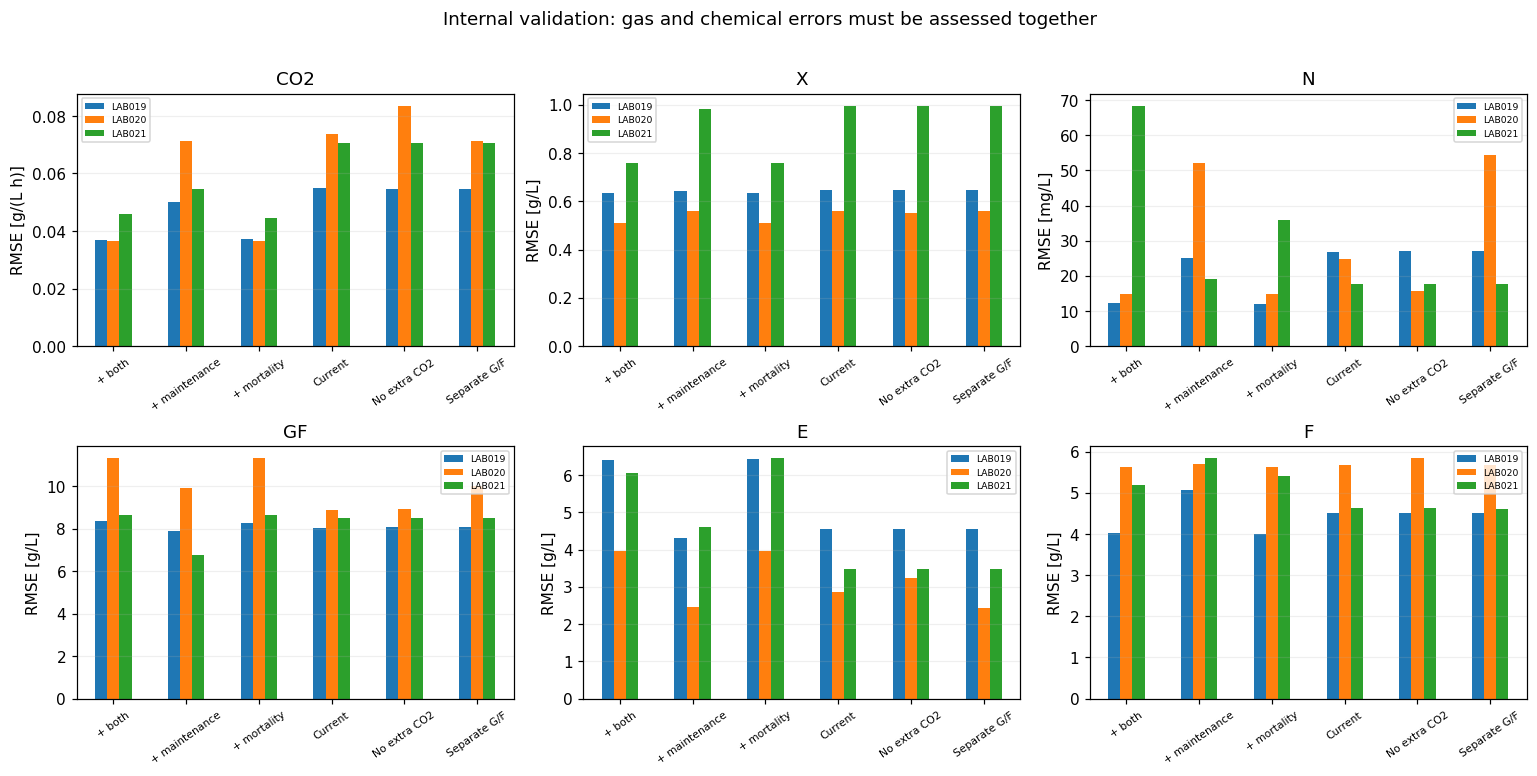

,structure,+ both,+ maintenance,+ mortality,Current,No extra CO2,Separate G/F
variable,unit,,,,,,
CO2,g/(L h),0.0397,0.0587,0.0393,0.0664,0.0696,0.0655
E,g/L,5.4746,3.7885,5.6151,3.6266,3.7589,3.4900
F,g/L,4.9460,5.5327,5.0040,4.9333,4.9873,4.9282
G,g/L,6.2682,6.0353,6.1901,6.2386,5.9622,6.2794
GF,g/L,9.4483,8.1939,9.4165,8.4897,8.5186,8.8717
N,mg/L,31.7945,32.0409,20.9070,23.0336,20.1080,33.0390
X,g/L,0.6347,0.7290,0.6349,0.7342,0.7323,0.7345


structure                 + both  + maintenance  ...  No extra CO2  Separate G/F
LAB    variable unit                             ...                            
LAB019 CO2      g/(L h)   0.0370         0.0501  ...        0.0547        0.0547
       E        g/L       6.3972         4.3100  ...        4.5667        4.5609
       F        g/L       4.0332         5.0716  ...        4.5056        4.5019
       G        g/L       6.4692         4.4349  ...        5.4880        5.4676
       GF       g/L       8.3542         7.8861  ...        8.0961        8.0761
       N        mg/L     12.2443        25.1238  ...       27.0867       27.0040
       X        g/L       0.6352         0.6428  ...        0.6478        0.6477
LAB020 CO2      g/(L h)   0.0364         0.0714  ...        0.0835        0.0713
       E        g/L       3.9701         2.4524  ...        3.2378        2.4404
       F        g/L       5.6144         5.6927  ...        5.8357        5.6831
       G        g/L       7.8897         7.3370  ...        6.4256        7.4017
       GF       g/L      11.3225         9.9059  ...        8.9364       10.0318
       N        mg/L     14.7544        51.9762  ...       15.6208       54.4593
       X        g/L       0.5118         0.5610  ...        0.5532        0.5604
LAB021 CO2      g/(L h)   0.0457         0.0545  ...        0.0705        0.0706
       E        g/L       6.0564         4.6033  ...        3.4722        3.4688
       F        g/L       5.1904         5.8338  ...        4.6206        4.5996
       G        g/L       4.4458         6.3342  ...        5.9731        5.9689
       GF       g/L       8.6682         6.7897  ...        8.5232        8.5073
       N        mg/L     68.3849        19.0227  ...       17.6163       17.6538
       X        g/L       0.7572         0.9832  ...        0.9958        0.9953

[21 rows x 6 columns]

In [9]:
plots.score_figures(STUDY)
CV_METRICS=METRICS.loc[METRICS.fold.ne('All development')]
display(CV_METRICS.groupby(['structure','variable','unit']).RMSE.mean().unstack('structure').round(4))
display(CV_METRICS.pivot(index=['LAB','variable','unit'],columns='structure',values='RMSE').round(4))

## 7. Coherencia de las incertidumbres y restricciones

La cobertura química mostrada compara las muestras con ±1.96 desviaciones del **estado**; no incluye una incertidumbre analítica independiente y no es una cobertura calibrada de observación. No se optimiza para alcanzar 95 %. El NIS y las bandas de innovaciones son diagnósticos aproximados: los recortes y la selección de datos impiden aplicar sin reservas una interpretación chi-cuadrado ideal. La autocorrelación se calcula conservando los huecos entre ventanas no asimiladas.

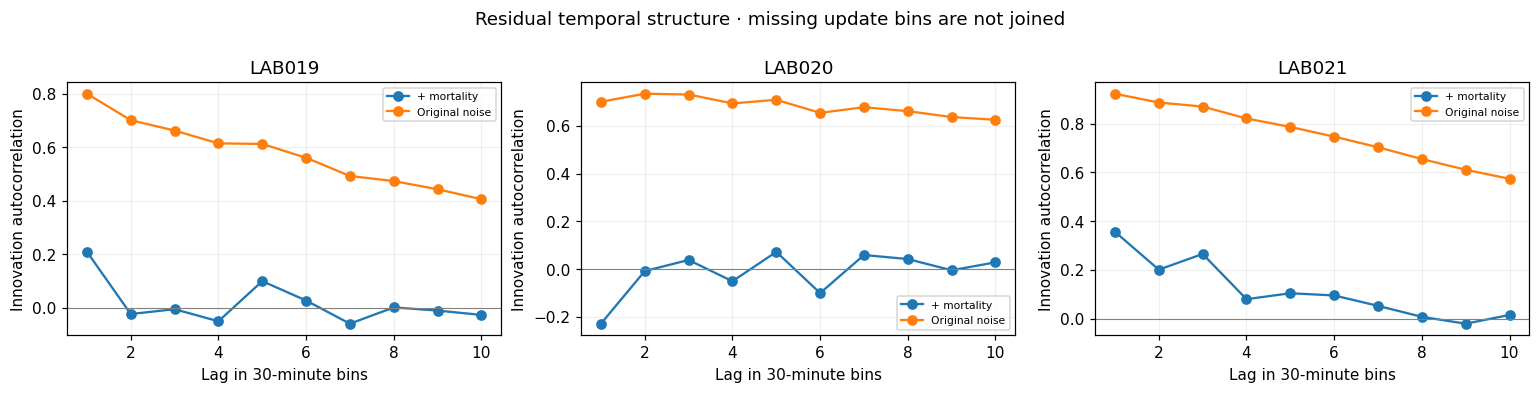

,LAB,updates,standardized_bias,mean_NIS,innovation_coverage95,lag1,clips,min_eigenvalue,fold,structure
0,LAB019,217,0.0734,0.6969,0.9724,0.7271,56,0.0,All development,Current
1,LAB020,223,-0.4137,0.9276,0.9417,0.7057,20,0.0,All development,Current
2,LAB021,166,-0.0056,1.9890,0.8072,0.8883,34,0.0,All development,Current
3,LAB019,217,-0.0087,1.0456,0.9493,0.2097,44,0.0,All development,+ mortality
4,LAB020,223,-0.1085,0.8342,0.9731,-0.2288,33,0.0,All development,+ mortality
5,LAB021,166,-0.1575,1.4416,0.9458,0.3562,25,0.0,All development,+ mortality
6,LAB019,217,0.2507,1.4061,0.9171,0.6672,63,0.0,All development,+ maintenance
7,LAB020,223,0.0327,0.7976,0.9686,0.3366,52,0.0,All development,+ maintenance
8,LAB021,166,0.3909,2.1809,0.8614,0.7428,59,0.0,All development,+ maintenance
9,LAB019,217,-0.0052,1.0444,0.9493,0.2081,39,0.0,All development,+ both


variable                         CO2      E      F      G     GF      N      X
fold             structure                                                    
All development  + both          NaN  0.667  0.944  0.540  0.225  0.667  0.300
                 + maintenance   NaN  0.667  1.000  0.714  0.856  0.583  0.333
                 + mortality     NaN  0.667  0.944  0.540  0.225  0.722  0.300
                 Current         NaN  0.733  0.878  0.397  0.201  0.583  0.400
                 No extra CO2    NaN  0.733  0.878  0.397  0.201  0.583  0.400
                 Original noise  NaN  0.733  0.790  0.508  0.164  0.583  0.300
                 Separate G/F    NaN  0.733  0.878  0.397  0.201  0.583  0.400
Leave LAB019 out + both          NaN  0.600  1.000  0.571  0.500  0.833  0.300
                 + maintenance   NaN  0.600  1.000  0.857  0.900  0.667  0.300
                 + mortality     NaN  0.600  1.000  0.571  0.200  0.750  0.300
                 Current         NaN  0.600  1.000  0.571  0.200  0.667  0.300
                 No extra CO2    NaN  0.600  1.000  0.571  0.200  0.667  0.300
                 Separate G/F    NaN  0.600  1.000  0.571  0.200  0.667  0.300
Leave LAB020 out + both          NaN  0.600  1.000  0.333  0.273  0.667  0.400
                 + maintenance   NaN  1.000  0.833  0.333  0.182  0.583  0.500
                 + mortality     NaN  0.600  1.000  0.333  0.273  0.667  0.400
                 Current         NaN  1.000  0.833  0.333  0.182  0.583  0.600
                 No extra CO2    NaN  0.800  1.000  0.333  0.182  0.583  0.500
                 Separate G/F    NaN  1.000  0.833  0.333  0.182  0.583  0.500
Leave LAB021 out + both          NaN  0.600  0.800  0.429  0.111  0.583  0.200
                 + maintenance   NaN  0.600  1.000  0.286  0.667  0.667  0.200
                 + mortality     NaN  0.600  0.800  0.571  0.111  0.583  0.200
                 Current         NaN  0.800  1.000  0.286  0.111  0.750  0.200
                 No extra CO2    NaN  0.800  1.000  0.286  0.111  0.750  0.200
                 Separate G/F    NaN  0.800  1.000  0.286  0.111  0.750  0.200

In [10]:
plots.innovation_figures(STUDY)
display(CHECKS.drop(columns='acf').round(4))
display(METRICS.groupby(['fold','structure','variable']).coverage95.mean().unstack('variable').round(3))
assert CHECKS.min_eigenvalue.min()>-1e-7

## 8. Estabilidad, límites e identificabilidad

Se comparan las amplitudes obtenidas con diferentes subconjuntos y diferentes inicializaciones. Los barridos son **condicionales**, manteniendo los otros parámetros fijos: no son perfiles reoptimizados ni intervalos de confianza. La SVD y el alineamiento de sensibilidades de predicción/varianza son comprobaciones locales de confundibilidad, no una demostración de identificabilidad global. La firma combina predicciones normalizadas por 0.04 y log-varianzas, por lo que su escala es explícitamente diagnóstica.

Local sensitivity singular values: [96.1124446036355, 52.74810137820366, 0.8320545150246758, 0.13891289081249333, 0.007879836786237474]
Negative score changes beyond a bound are evidence that the original search range did not bracket a local minimum.


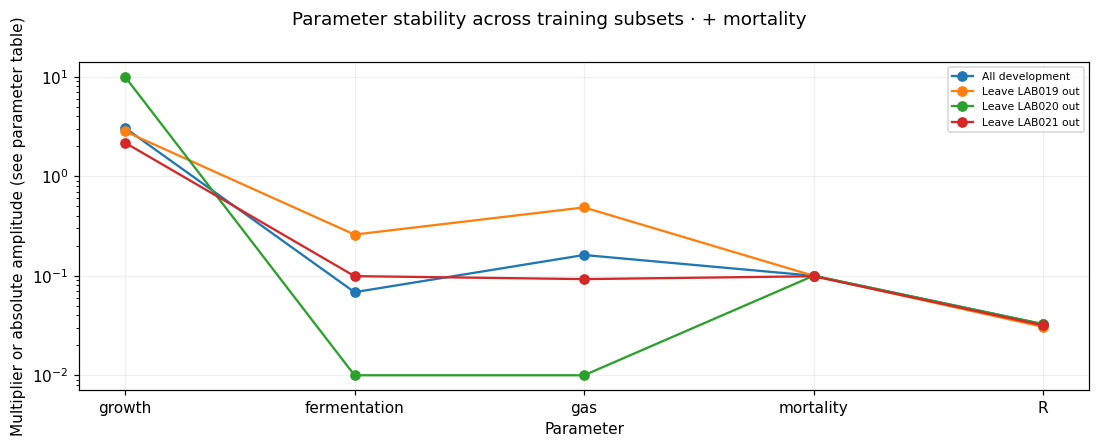

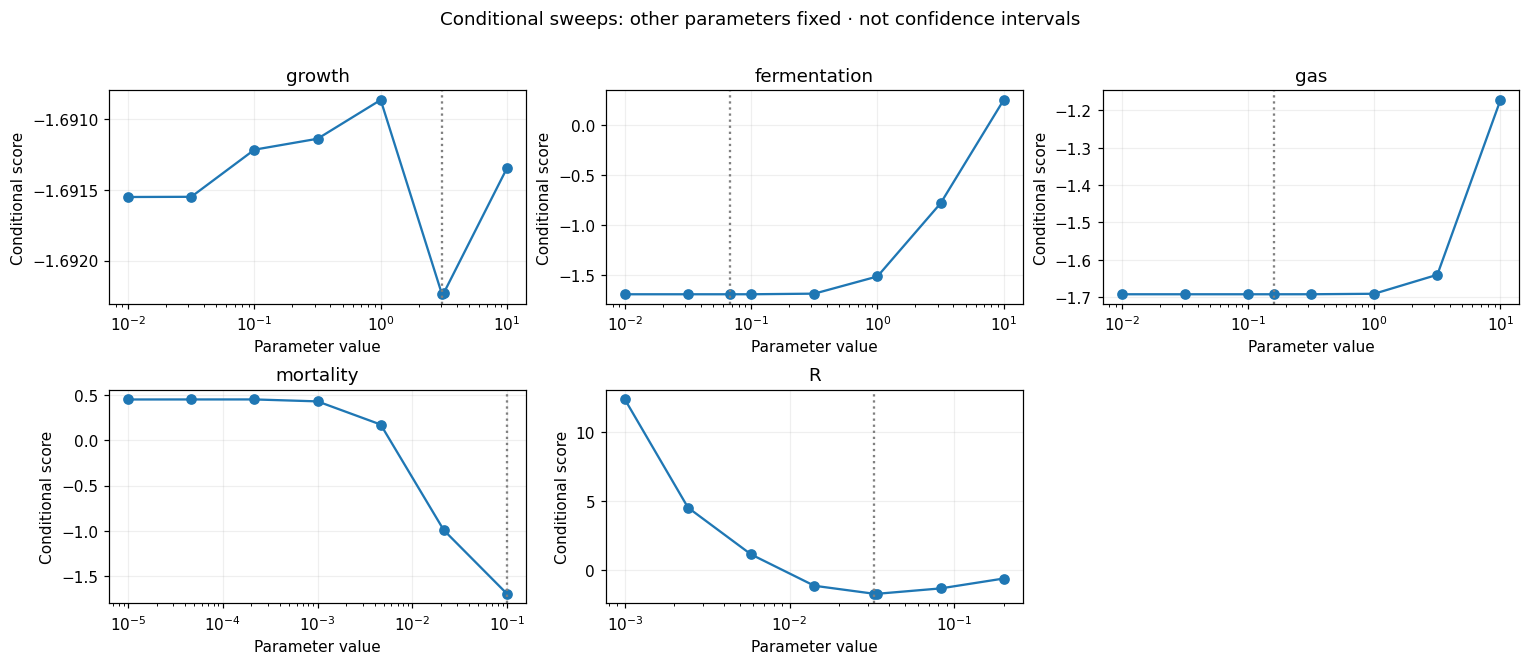

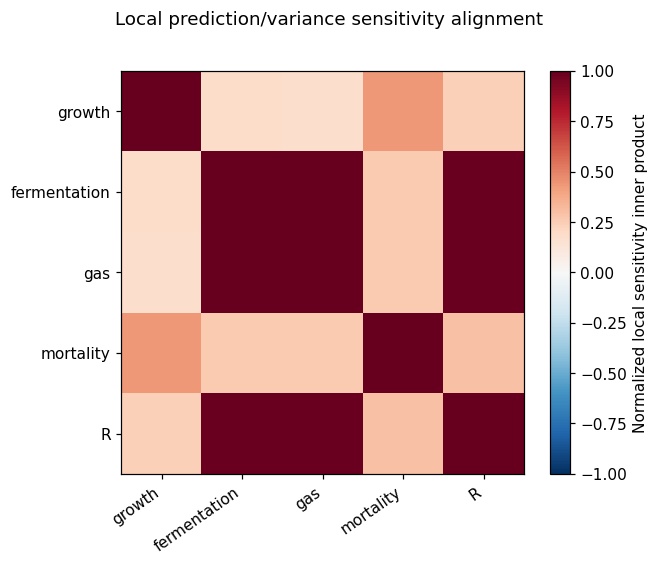

,fold,structure,Rsd,bounds,converged_starts,score_spread,sigma_growth,sigma_G,sigma_F,sigma_CO2,sigma_mortality,sigma_maintenance
0,All development,Current,0.067306,growth,2,0.000893,0.030000,0.022905,0.022905,0.022558,0.000000,0.000000
1,All development,+ mortality,0.032632,mortality,2,0.000762,0.009173,0.005470,0.005470,0.001616,0.100000,0.000000
2,All development,+ maintenance,0.046840,"growth, fermentation, gas, maintenance",2,0.242430,0.030000,0.000800,0.000800,0.000100,0.000000,1.000000
3,All development,+ both,0.032299,mortality,2,0.000608,0.000304,0.009780,0.009780,0.000587,0.099890,0.073847
4,All development,Separate G/F,0.068059,growth,2,0.000561,0.030000,0.039298,0.011096,0.009540,0.000000,0.000000
5,All development,No extra CO2,0.070299,growth,2,0.115821,0.030000,0.002495,0.002495,0.000000,0.000000,0.000000
6,Leave LAB019 out,Current,0.067198,growth,2,0.003029,0.030000,0.005845,0.005845,0.007538,0.000000,0.000000
7,Leave LAB019 out,+ mortality,0.030625,mortality,2,0.002916,0.008475,0.020740,0.020740,0.004860,0.099987,0.000000
8,Leave LAB019 out,+ maintenance,0.044864,"growth, fermentation, maintenance",2,0.320599,0.030000,0.000800,0.000800,0.007842,0.000000,1.000000
9,Leave LAB019 out,+ both,0.012299,mortality,2,0.017883,0.014077,0.050914,0.050914,0.005041,0.099886,0.624241


fold                        All development  ...  Leave LAB021 out
structure     parameter                      ...                  
+ both        R                    0.032299  ...          0.007912
              fermentation         0.122250  ...          0.649910
              gas                  0.058705  ...          0.824294
              growth               0.101242  ...          2.688090
              maintenance          0.073847  ...          0.110778
              mortality            0.099890  ...          0.083290
+ maintenance R                    0.046840  ...          0.043054
              fermentation         0.010006  ...          0.010008
              gas                  0.010000  ...          0.010000
              growth              10.000000  ...         10.000000
              maintenance          1.000000  ...          1.000000
+ mortality   R                    0.032632  ...          0.031743
              fermentation         0.068372  ...          0.099133
              gas                  0.161636  ...          0.092517
              growth               3.057796  ...          2.173030
              mortality            0.100000  ...          0.098834
Current       R                    0.067306  ...          0.064299
              fermentation         0.286315  ...          0.159672
              gas                  2.255781  ...          1.161820
              growth              10.000000  ...         10.000000
No extra CO2  R                    0.070299  ...          0.065427
              fermentation         0.031191  ...          0.036060
              growth              10.000000  ...         10.000000
Separate G/F  R                    0.068059  ...          0.057548
              ferm_F               0.138701  ...          0.040401
              ferm_G               0.491228  ...          0.051242
              gas                  0.954009  ...          3.551897
              growth              10.000000  ...          9.994100

[28 rows x 4 columns]

,structure,parameter,factor_beyond_bound,score,delta_from_fit
0,Current,growth,2.0,-1.123734,-5.703085e-02
1,Current,growth,4.0,-1.248378,-1.816750e-01
2,+ mortality,mortality,2.0,-1.684546,7.692493e-03
3,+ mortality,mortality,4.0,-1.509948,1.822898e-01
4,+ maintenance,growth,2.0,-1.416672,-1.004318e-01
5,+ maintenance,growth,4.0,-1.489677,-1.734373e-01
6,+ maintenance,fermentation,2.0,-1.316241,-9.973927e-07
7,+ maintenance,fermentation,4.0,-1.316241,-1.246346e-06
8,+ maintenance,gas,2.0,-1.316240,-8.424858e-09
9,+ maintenance,gas,4.0,-1.316240,-1.045459e-08


In [11]:
PARAMETERS=plots.parameter_figures(STUDY)
fit_rows=[]
for fit in STUDY['fits']:
    fit_rows.append(dict(fold=fit['fold'],structure=fit['structure'],Rsd=fit['Rsd'],bounds=', '.join(fit['at_bound']),
        converged_starts=sum(r['success'] for r in fit['runs']),
        score_spread=max(r['score'] for r in fit['runs'])-min(r['score'] for r in fit['runs']),
        sigma_growth=fit['sigma'][0],sigma_G=fit['sigma'][1],sigma_F=fit['sigma'][2],sigma_CO2=fit['sigma'][3],
        sigma_mortality=fit['sigma'][4],sigma_maintenance=fit['sigma'][5]))
FIT_TABLE=pd.DataFrame(fit_rows);display(FIT_TABLE)
display(PARAMETERS.pivot(index=['structure','parameter'],columns='fold',values='value'))
print('Local sensitivity singular values:',STUDY['sensitivity']['singular_values'])
FIT_TABLE.to_csv(OUT/'fitted_amplitudes.csv',index=False)
# Probe beyond active bounds without using the probes to select a structure.
BOUND_PROBES=[]
for fit in STUDY['fits']:
    if fit['fold']!='All development':continue
    names=fit['names'];xx=np.array(fit['x']);bounds=core.bounds_for(names)
    for name in fit['at_bound']:
        j=names.index(name);direction=-1 if xx[j]-bounds[j][0]<bounds[j][1]-xx[j] else 1
        for factor in [2.,4.]:
            trial=xx.copy();trial[j]+=direction*np.log10(factor)
            score=core.objective(trial,names,DATA,core.LABS,np.array([STUDY['gas'][0]['kLa'],STUDY['gas'][0]['gain']]))
            BOUND_PROBES.append(dict(structure=fit['structure'],parameter=name,factor_beyond_bound=factor,
                score=score,delta_from_fit=score-fit['score']))
BOUND_PROBES=pd.DataFrame(BOUND_PROBES)
display(BOUND_PROBES)
BOUND_PROBES.to_csv(OUT/'bound_sensitivity.csv',index=False)
print('Negative score changes beyond a bound are evidence that the original search range did not bracket a local minimum.')


## 9. Trayectorias con incertidumbre: efecto del ajuste de ruido

Se comparan el ruido original y el candidato de menor criterio interno de CO₂, ambos con la **misma** calibración de gas sobre todo el desarrollo. Las figuras no son resultados de validación independiente. El CO₂ es previo a la corrección; los estados químicos son posteriores a la actualización cuando corresponde. Se conservan las muestras iniciales y NUT; no se ocultan intervalos negativos de la aproximación gaussiana.

**Lectura de las leyendas:** Original noise significa las matrices originales aplicadas a la calibración de gas reajustada en este análisis. La reproducción con la calibración archivada aparece en la sección 2 y en la tabla que separa gas y ruido. Un cambio de la capa de gas puede inducir trayectorias químicas distintas aunque las matrices de ruido no cambien.


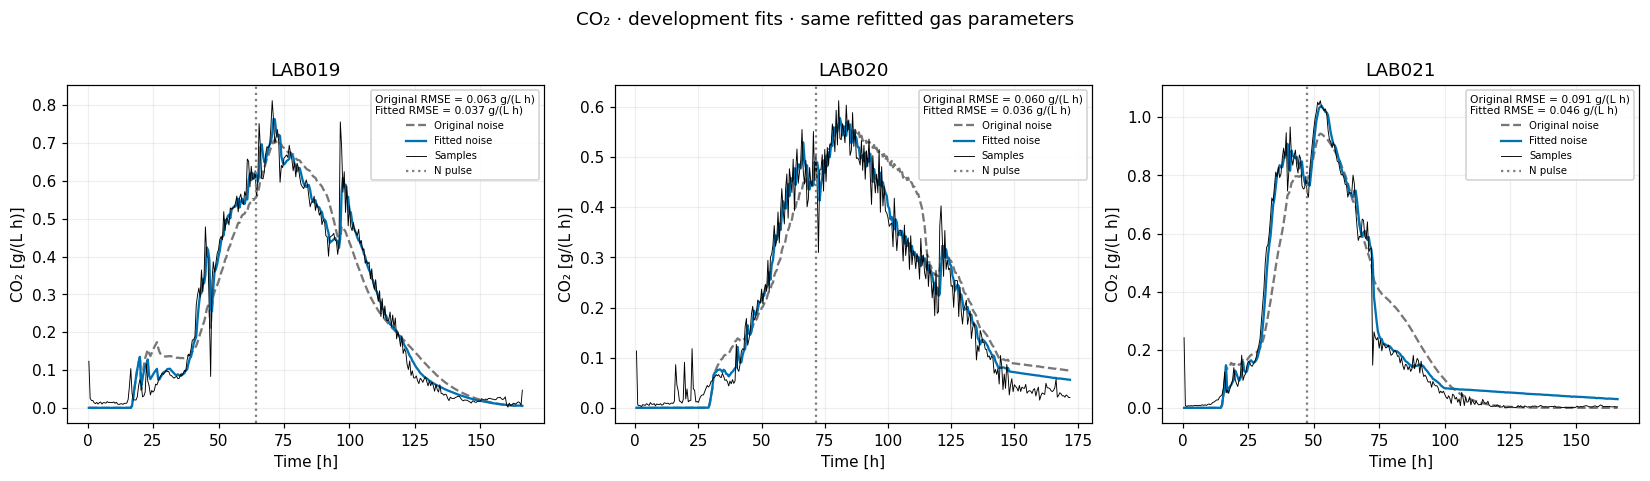

In [12]:
plots.trajectories(DATA,CHEM,RECORDS,LEADER,'CO2','CO₂')

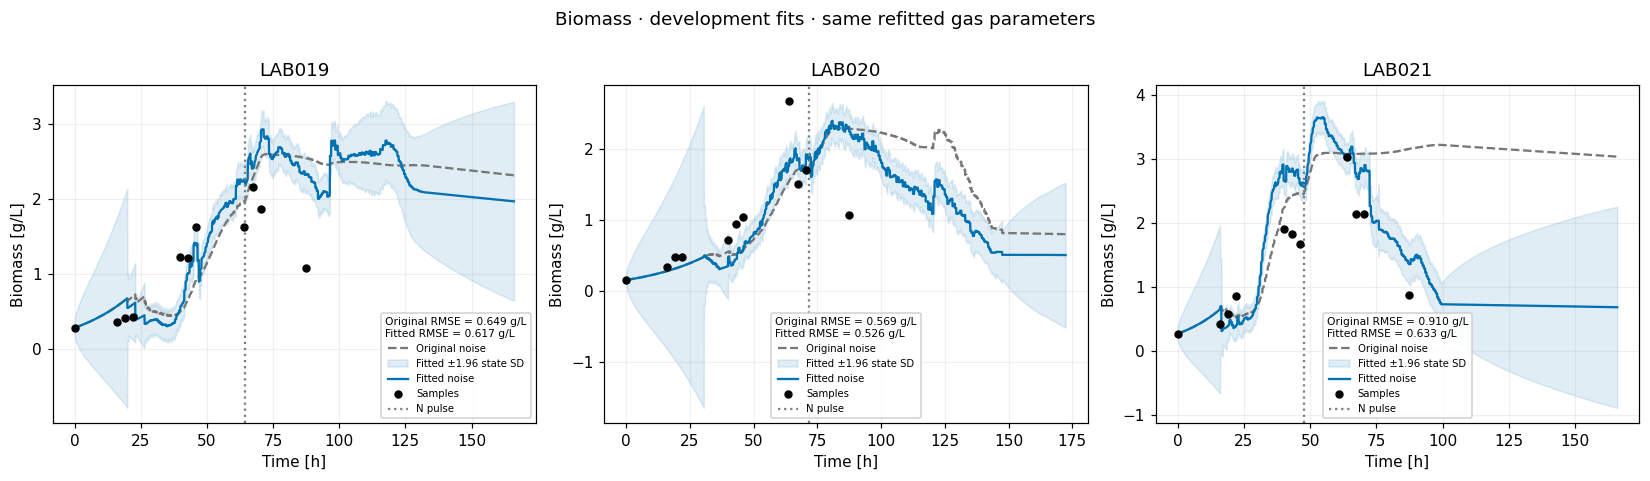

In [13]:
plots.trajectories(DATA,CHEM,RECORDS,LEADER,'X','Biomass')

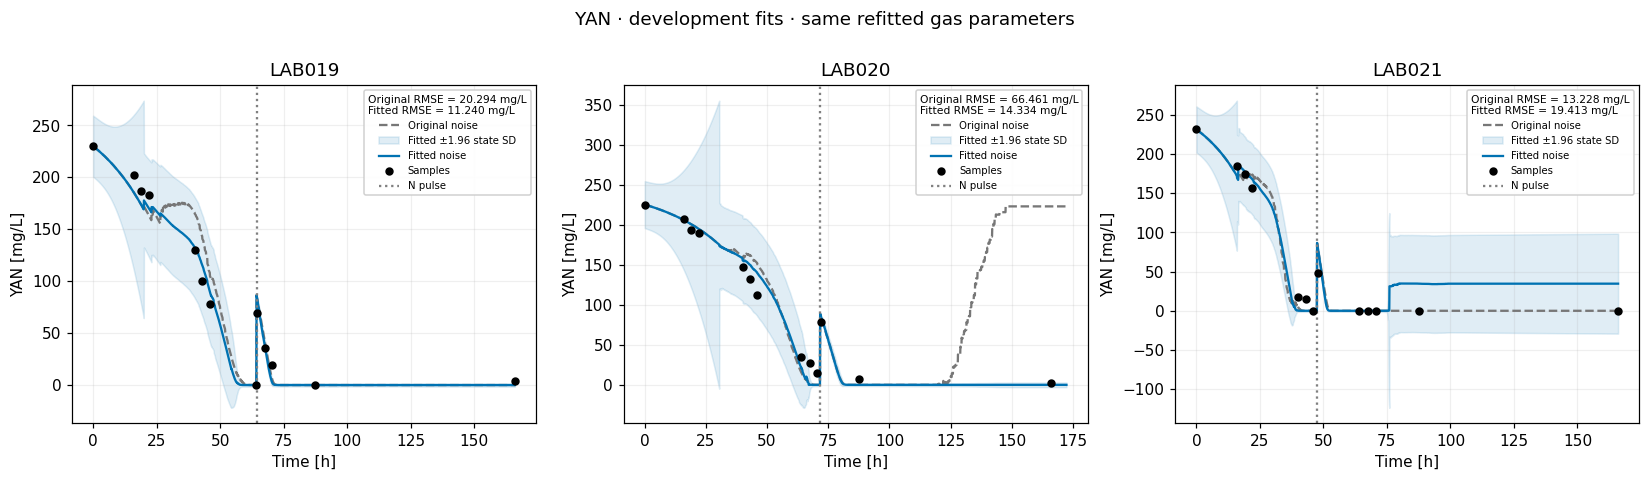

In [14]:
plots.trajectories(DATA,CHEM,RECORDS,LEADER,'N','YAN')

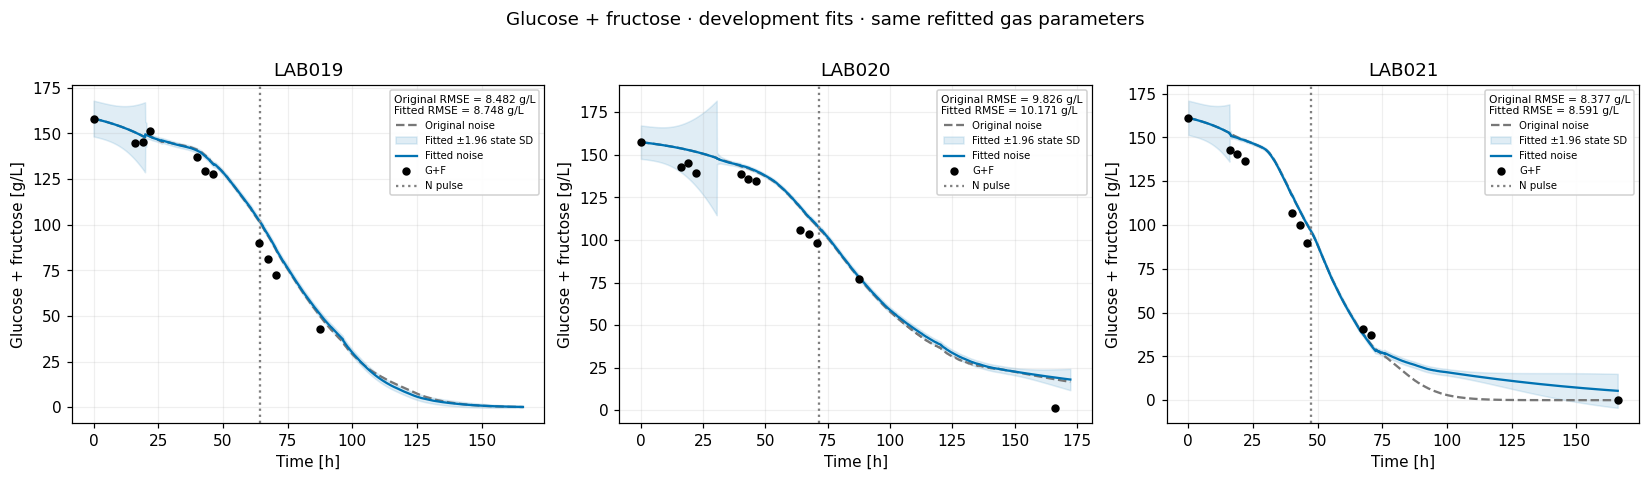

In [15]:
plots.trajectories(DATA,CHEM,RECORDS,LEADER,'GF','Glucose + fructose')

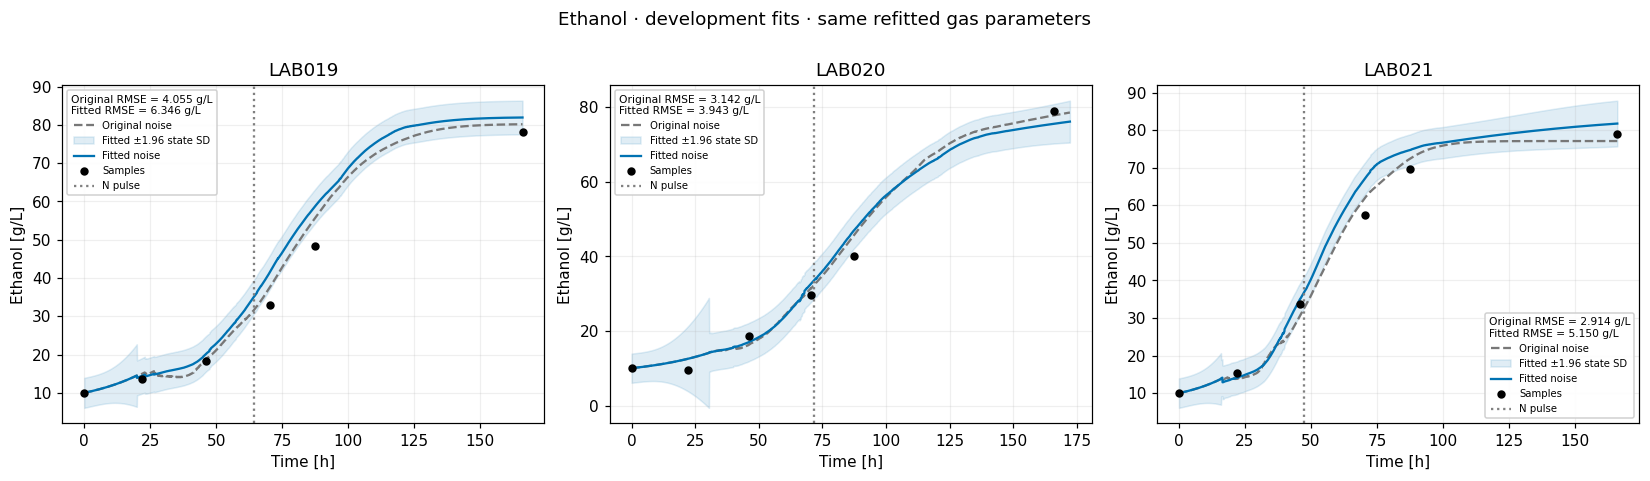

In [16]:
plots.trajectories(DATA,CHEM,RECORDS,LEADER,'E','Ethanol')

## 9b. Comprobaciones que impiden sobreinterpretar el ajuste

Una columna de mortalidad igual a −1 solo en X, con ruido gaussiano simétrico y aditivo, es matemáticamente equivalente en covarianza a una perturbación independiente de biomasa con signo +1. Una mejora con esa columna **no identifica la mortalidad como causa física**; tampoco estima la incertidumbre de kd. El ruido puede corregir biomasa en ambos sentidos.

Los límites influyen en la comparación: si aumentar la amplitud de crecimiento más allá del rango sigue mejorando el criterio, la clasificación entre estructuras queda condicionada por esos límites. Los barridos fuera del rango detectan esta situación, pero no reemplazan una nueva validación con rangos ampliados. No se acepta una estructura definitiva en este notebook.

También revisamos aumentos tardíos de YAN sin nueva nutrición. Son cambios del estimador, no producción biológica de nitrógeno. Las bandas gaussianas pueden cruzar cero y las covarianzas tras recortar los estados son aproximadas.


In [17]:
anomalies=[]
for label,records in [('Archived gas + original noise',ARCHIVED),('Refitted gas + original noise',{lab:RECORDS['Original noise',lab] for lab in core.LABS}),('Refitted gas + fitted candidate',{lab:RECORDS[LEADER,lab] for lab in core.LABS})]:
    for lab in core.LABS:
        frame=records[lab][0];grid=DATA[lab]['grid'];late=grid>100
        rises=(np.diff(frame[:,1])>1e-8)&(grid[1:]>100)&(DATA[lab]['doses'][1:]==0)
        anomalies.append(dict(case=label,LAB=lab,max_YAN_after_100h_mg_L=float(frame[late,1].max()*1000),positive_YAN_increments_after_100h=int(rises.sum())))
display(pd.DataFrame(anomalies))
pd.DataFrame(anomalies).to_csv(OUT/'late_YAN_diagnostics.csv',index=False)
multistart=[]
for fit in STUDY['fits']:
    if fit['fold']!='All development':continue
    for search in fit['runs']:
        sig,rsd=core.decode(np.array(search['x']),fit['names'])
        multistart.append(dict(structure=fit['structure'],start=search['start'],score=search['score'],converged=search['success'],
            sigma_growth=sig[0],sigma_G=sig[1],sigma_F=sig[2],sigma_CO2=sig[3],sigma_mortality=sig[4],sigma_maintenance=sig[5],Rsd=rsd))
display(pd.DataFrame(multistart))
pd.DataFrame(multistart).to_csv(OUT/'multistart_amplitudes.csv',index=False)


,case,LAB,max_YAN_after_100h_mg_L,positive_YAN_increments_after_100h
0,Archived gas + original noise,LAB019,0.001285,27
1,Archived gas + original noise,LAB020,0.004012,74
2,Archived gas + original noise,LAB021,0.000020,0
3,Refitted gas + original noise,LAB019,0.000517,29
4,Refitted gas + original noise,LAB020,223.687403,82
5,Refitted gas + original noise,LAB021,0.000032,0
6,Refitted gas + fitted candidate,LAB019,0.010281,40
7,Refitted gas + fitted candidate,LAB020,0.042784,57
8,Refitted gas + fitted candidate,LAB021,34.589228,0


,structure,start,score,converged,sigma_growth,sigma_G,sigma_F,sigma_CO2,sigma_mortality,sigma_maintenance,Rsd
0,Current,0,-1.066703,True,0.030000,0.022905,0.022905,0.022558,0.00000,0.000000,0.067306
1,Current,1,-1.065810,True,0.030000,0.024447,0.024447,0.003999,0.00000,0.000000,0.069012
2,+ mortality,0,-1.691476,True,0.028594,0.000800,0.000800,0.000100,0.10000,0.000000,0.032802
3,+ mortality,1,-1.692238,True,0.009173,0.005470,0.005470,0.001616,0.10000,0.000000,0.032632
4,+ maintenance,0,-1.073811,True,0.030000,0.017501,0.017501,0.034126,0.00000,0.038160,0.062075
5,+ maintenance,1,-1.316240,True,0.030000,0.000800,0.000800,0.000100,0.00000,1.000000,0.046840
6,+ both,0,-1.691280,True,0.030000,0.006187,0.006187,0.004219,0.10000,0.000275,0.031978
7,+ both,1,-1.691888,True,0.000304,0.009780,0.009780,0.000587,0.09989,0.073847,0.032299
8,Separate G/F,0,-1.068544,True,0.030000,0.039298,0.011096,0.009540,0.00000,0.000000,0.068059
9,Separate G/F,1,-1.067982,True,0.029991,0.039201,0.017386,0.007989,0.00000,0.000000,0.068229


## 10. Conclusiones y decisiones pendientes

La tabla siguiente explicita el criterio de CO₂, los conflictos con estados químicos y las advertencias de cada alternativa. No se publica una nueva calibración oficial ni se modifica la configuración de ningún estimador. La estructura actual tiene fuentes de flujo escogidas, no una validación experimental de cuatro mecanismos independientes.

In [18]:
cv_score=SCORES.loc[SCORES.fold.ne('All development')].groupby('structure').score.mean()
cv_rmse=CV_METRICS.groupby(['structure','variable']).RMSE.mean().unstack()
DECISION=cv_rmse.join(cv_score.rename('CO2_quasi_score'))
for structure in DECISION.index:
    subset=SCORES.loc[SCORES.structure.eq(structure)]
    DECISION.loc[structure,'any_bound']=bool(subset.at_bound.str.len().gt(0).any())
    DECISION.loc[structure,'all_searches_converged']=bool(subset.converged.all())
display(DECISION.round(4))
reference=DECISION.loc['Current'];candidate=DECISION.loc[LEADER]
text=f"**Candidato por predicción de CO₂:** {LEADER}. Es una clasificación de desarrollo, no una elección definitiva. "
conflicts=[s for s in ['X','N','GF','E'] if candidate[s]>reference[s]]
text+='Estados con mayor RMSE interno que la estructura actual ajustada: '+(', '.join(conflicts) if conflicts else 'ninguno de X, N, GF y E')+'. '
if candidate['any_bound']:text+='Hay parámetros en límites de búsqueda: las amplitudes no pueden declararse identificadas con precisión. '
if not candidate['all_searches_converged']:text+='Alguna búsqueda no convergió; su comparación es provisional. '
text+='Los barridos fuera de límites mejoran algunas alternativas; esta clasificación depende del rango y no decide una estructura definitiva. '
text+='La estabilidad entre inicios, las innovaciones y las coberturas deben evaluarse conjuntamente. Los datos no garantizan una descomposición única entre Q y R.'
display(Markdown(text))
DECISION.to_csv(OUT/'decision_table.csv')
core.verify_protected(ROOT,PROTECTED)
print('Protected existing notebooks, source and configurations unchanged:',len(PROTECTED))
print('Every fitting/selection dataset:',STUDY['allowed_labs'])
print('No LAB016–018 result entered fitting, source selection or diagnostics.')

Protected existing notebooks, source and configurations unchanged: 132
Every fitting/selection dataset: ['LAB019', 'LAB020', 'LAB021']
No LAB016–018 result entered fitting, source selection or diagnostics.


,CO2,E,F,G,GF,N,X,CO2_quasi_score,any_bound,all_searches_converged
structure,,,,,,,,,,
+ both,0.0397,5.4746,4.9460,6.2682,9.4483,31.7945,0.6347,-1.6171,True,False
+ maintenance,0.0587,3.7885,5.5327,6.0353,8.1939,32.0409,0.7290,-1.0786,True,True
+ mortality,0.0393,5.6151,5.0040,6.1901,9.4165,20.9070,0.6349,-1.6817,True,True
Current,0.0664,3.6266,4.9333,6.2386,8.4897,23.0336,0.7342,-1.0190,True,True
No extra CO2,0.0696,3.7589,4.9873,5.9622,8.5186,20.1080,0.7323,-1.0073,True,True
Separate G/F,0.0655,3.4900,4.9282,6.2794,8.8717,33.0390,0.7345,-1.0301,True,True


**Candidato por predicción de CO₂:** + mortality. Es una clasificación de desarrollo, no una elección definitiva. Estados con mayor RMSE interno que la estructura actual ajustada: GF, E. Hay parámetros en límites de búsqueda: las amplitudes no pueden declararse identificadas con precisión. Los barridos fuera de límites mejoran algunas alternativas; esta clasificación depende del rango y no decide una estructura definitiva. La estabilidad entre inicios, las innovaciones y las coberturas deben evaluarse conjuntamente. Los datos no garantizan una descomposición única entre Q y R.

## Referencias y alcance del respaldo

- [Särkkä y Svensson, Bayesian Filtering and Smoothing, capítulo 16](https://users.aalto.fi/~ssarkka/pub/bfs_book_2023_online.pdf): estimación de parámetros mediante filtros y verosimilitud aproximada.
- [MathWorks, kalman, Algorithms](https://www.mathworks.com/help/control/ref/ss.kalman.html): covarianza de fuentes y transformación mediante su matriz de entrada al sistema.
- [Liger-Belair et al., 2023](https://doi.org/10.1021/acsomega.3c01812): correlación de solubilidad usada por el modelo. Su extrapolación a mosto fermentando y la presión parcial asumida siguen siendo limitaciones.

Estas referencias respaldan métodos y relaciones generales. **No respaldan las amplitudes numéricas elegidas previamente ni prueban que nuestras seis fuentes candidatas sean suficientes.** La transferencia, el mapeo local del ruido y los recortes siguen siendo aproximaciones de esta implementación.